# Unsupervised Learning: Fuzzy C-Means Clustering

## 0. Setup and Configuration
Before training our K-Means model, we import the core scientific libraries and configure our data source. Use the code block below to either load your own dataset or default to a custom CSV file.

In [ ]:
%pip install -q scikit-fuzzy

In [2]:
!pip install -q scikit-fuzzy
import numpy as np
import pandas as pd
import os
import skfuzzy as fuzz

# --- Custom Dataset Configuration ---
# Configured with relative paths for seamless local VS Code and repo execution
USE_CUSTOM_DATA = True
DATASET_CANDIDATES = [
    os.path.join('..', 'datasets', 'student_performance.csv'),
    os.path.join('datasets', 'student_performance.csv'),
    'student_performance.csv',
    '/content/student_performance (1).csv'
]
DATASET_PATH = next((p for p in DATASET_CANDIDATES if os.path.exists(p)), DATASET_CANDIDATES[0])

if USE_CUSTOM_DATA:
    if os.path.exists(DATASET_PATH):
        # Load your dataset
        df_custom = pd.read_csv(DATASET_PATH)
        print(f"Loaded dataset from: {DATASET_PATH} with shape: {df_custom.shape}")
        print("Columns:", df_custom.columns.tolist())
        display(df_custom.head())
    else:
        print(f"Warning: {DATASET_PATH} not found. Please verify dataset location.")
else:
    print("Using default synthetic data generator in Step 1.")


Loaded custom dataset with shape: (14003, 16)
Columns: ['StudyHours', 'Attendance', 'Resources', 'Extracurricular', 'Motivation', 'Internet', 'Gender', 'Age', 'LearningStyle', 'OnlineCourses', 'Discussions', 'AssignmentCompletion', 'ExamScore', 'EduTech', 'StressLevel', 'FinalGrade']


,StudyHours,Attendance,Resources,Extracurricular,Motivation,Internet,Gender,Age,LearningStyle,OnlineCourses,Discussions,AssignmentCompletion,ExamScore,EduTech,StressLevel,FinalGrade
0,19,64,1,0,0,1,0,19,2,8,1,59,40,0,1,3
1,19,64,1,0,0,1,0,23,3,16,0,90,66,0,1,2
2,19,64,1,0,0,1,0,28,1,19,0,67,99,1,1,0
3,19,64,1,1,0,1,0,19,2,8,1,59,40,0,1,3
4,19,64,1,1,0,1,0,23,3,16,0,90,66,0,1,2


## 1. Training and Predicting
In this section, we generate synthetic data, instantiate the `KMeans` model from `scikit-learn`, fit the model, and predict the cluster assignments.

In [4]:
import numpy as np
import pandas as pd
import skfuzzy as fuzz
from sklearn.datasets import make_blobs

# 1. Determine data source dynamically
if 'USE_CUSTOM_DATA' in globals() and USE_CUSTOM_DATA and 'df_custom' in globals():
    print("Using custom dataset configured in Step 0.")
    df = df_custom.copy()
    # Select numeric features for clustering
    X = df[["StudyHours", "ExamScore"]]
    if X.shape[1] < 2:
        raise ValueError("Custom dataset must contain at least 2 numerical features for this template.")
else:
    print("Using default synthetic data generator.")
    # Generate synthetic 2D data for demonstration
    X, y_true = make_blobs(n_samples=1000, centers=4, cluster_std=0.60, random_state=67)
    df = pd.DataFrame(X, columns=['Feature_1', 'Feature_2'])

# 2. Define Fuzzy C-Means parameters
n_clusters = 3
m = 2.0  # Fuzziness exponent (default is usually 2.0)

# skfuzzy expects data shape as (n_features, n_samples)
# We transpose X for the algorithm
cntr, u, u0, d, jm, p, fpc = fuzz.cmeans(
    data=X.T,
    c=n_clusters,
    m=m,
    error=0.005,
    maxiter=1000,
    init=None
)

# 3. Predict cluster assignments based on the highest membership value
df['Cluster'] = np.argmax(u, axis=0)

# Store membership values for each cluster in our dataframe
for i in range(n_clusters):
    df[f'Membership_Cluster_{i}'] = u[i]

# Save centroids for downstream steps
centroids = cntr

display(df.head())

Using custom dataset configured in Step 0.


,StudyHours,Attendance,Resources,Extracurricular,Motivation,Internet,Gender,Age,LearningStyle,OnlineCourses,Discussions,AssignmentCompletion,ExamScore,EduTech,StressLevel,FinalGrade,Cluster,Membership_Cluster_0,Membership_Cluster_1,Membership_Cluster_2
0,19,64,1,0,0,1,0,19,2,8,1,59,40,0,1,3,1,0.084571,0.886527,0.028902
1,19,64,1,0,0,1,0,23,3,16,0,90,66,0,1,2,0,0.926293,0.050816,0.022891
2,19,64,1,0,0,1,0,28,1,19,0,67,99,1,1,0,2,0.068131,0.023301,0.908569
3,19,64,1,1,0,1,0,19,2,8,1,59,40,0,1,3,1,0.084571,0.886527,0.028902
4,19,64,1,1,0,1,0,23,3,16,0,90,66,0,1,2,0,0.926293,0.050816,0.022891


## 2. Inspecting Created Clusters
Here, we examine the resulting cluster properties, including cluster centers (centroids) and the distribution of samples across clusters.

In [5]:
# 1. Inspect fuzzy cluster centroids
centroids_df = pd.DataFrame(centroids, columns=['StudyHours', 'ExamScore'])
centroids_df.index.name = 'Cluster'
print("--- Fuzzy Cluster Centroids ---")
display(centroids_df)

# 2. Inspect size of each cluster based on hard (argmax) assignment
print("\n--- Sample Count per Dominant Cluster ---")
display(df['Cluster'].value_counts().sort_index().to_frame(name='Count'))

# 3. Inspect average membership values to see how "fuzzy" the assignments are
print("\n--- Average Membership Grade per Cluster ---")
membership_cols = [f'Membership_Cluster_{i}' for i in range(n_clusters)]
display(df[membership_cols].mean().to_frame(name='Average Membership'))

--- Fuzzy Cluster Centroids ---


,StudyHours,ExamScore
Cluster,,
0,19.806668,69.865331
1,20.012123,49.171966
2,20.094152,91.094138



--- Sample Count per Dominant Cluster ---


,Count
Cluster,
0,4733
1,4492
2,4778



--- Average Membership Grade per Cluster ---


,Average Membership
Membership_Cluster_0,0.344458
Membership_Cluster_1,0.321447
Membership_Cluster_2,0.334094


## 3. Visualizing the Results
We use `matplotlib` and `seaborn` to visualize the clusters along with their respective centroids.

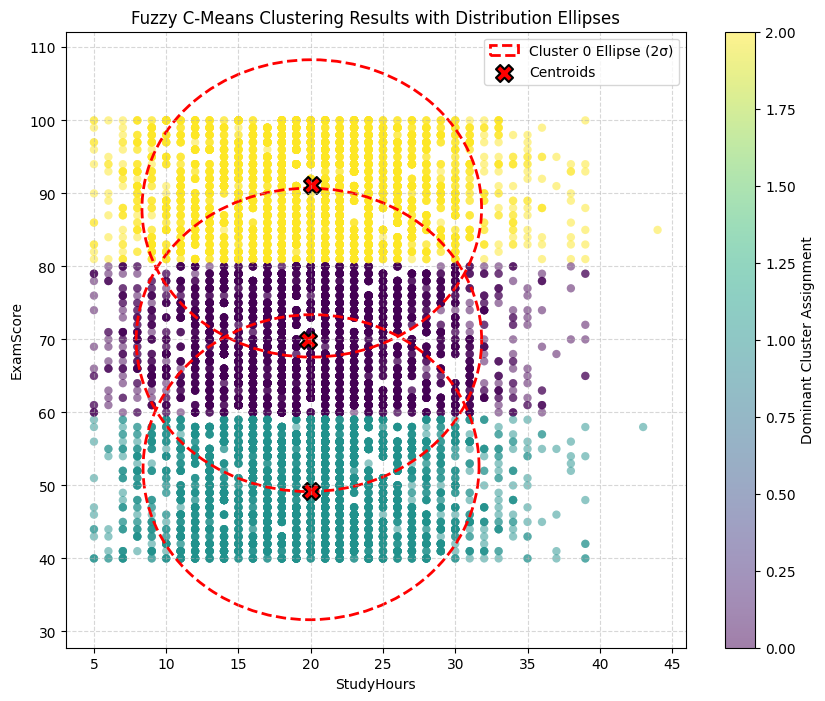

In [7]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.patches import Ellipse

def draw_fuzzy_ellipse(x, y, weights, ax, n_std=2.0, **kwargs):
    """Draw an ellipse showing the covariance of a fuzzy cluster."""
    # Normalize weights
    weights = weights / np.sum(weights)

    # Fuzzy mean
    mean_x = np.sum(x * weights)
    mean_y = np.sum(y * weights)

    # Fuzzy covariance matrix
    dx = x - mean_x
    dy = y - mean_y
    cov_xx = np.sum(weights * dx * dx)
    cov_yy = np.sum(weights * dy * dy)
    cov_xy = np.sum(weights * dx * dy)

    cov = np.array([[cov_xx, cov_xy], [cov_xy, cov_yy]])

    # Eigenvalues and eigenvectors of the covariance matrix
    vals, vecs = np.linalg.eigh(cov)
    order = vals.argsort()[::-1]
    vals, vecs = vals[order], vecs[:, order]

    # Calculate angle of rotation in degrees
    theta = np.degrees(np.arctan2(*vecs[:, 0][::-1]))

    # Width and height of ellipse
    width, height = 2 * n_std * np.sqrt(np.abs(vals))

    ellipse = Ellipse(xy=(mean_x, mean_y), width=width, height=height, angle=theta, **kwargs)
    return ax.add_patch(ellipse)

fig, ax = plt.subplots(figsize=(10, 8))

# Plot data points colored by their dominant cluster
scatter = ax.scatter(
    df['StudyHours'],
    df['ExamScore'],
    c=df['Cluster'],
    cmap='viridis',
    alpha=0.5,
    edgecolors='none'
)

# Draw an ellipse for each fuzzy cluster based on membership weights
colors = ['purple', 'teal', 'gold']
for i in range(n_clusters):
    weights = df[f'Membership_Cluster_{i}'].values
    # Draw a 2-standard-deviation ellipse to capture the cluster distribution shape
    draw_fuzzy_ellipse(
        df['StudyHours'].values,
        df['ExamScore'].values,
        weights,
        ax,
        n_std=2.0,
        edgecolor='red',
        linestyle='--',
        linewidth=2,
        facecolor='none',
        label=f'Cluster {i} Ellipse (2σ)' if i == 0 else ""
    )

# Plot cluster centroids
ax.scatter(
    centroids[:, 0],
    centroids[:, 1],
    c='red',
    s=150,
    marker='X',
    label='Centroids',
    edgecolors='black',
    linewidths=1.5
)

ax.set_title('Fuzzy C-Means Clustering Results with Distribution Ellipses')
ax.set_xlabel('StudyHours')
ax.set_ylabel('ExamScore')
fig.colorbar(scatter, ax=ax, label='Dominant Cluster Assignment')
ax.legend()
ax.grid(True, linestyle='--', alpha=0.5)
# Save visualization to results directory
os.makedirs(os.path.join('..', 'results', 'fuzzy_cmeans'), exist_ok=True)
os.makedirs(os.path.join('results', 'fuzzy_cmeans'), exist_ok=True)
save_path = os.path.join('..', 'results', 'fuzzy_cmeans', 'fuzzy_cmeans_results.png') if os.path.exists(os.path.join('..', 'results')) else os.path.join('results', 'fuzzy_cmeans', 'fuzzy_cmeans_results.png')
plt.savefig(save_path, dpi=300, bbox_inches='tight')
print(f"Saved figure to: {save_path}")
plt.show()

## 4. Interpretation Guide for the Results

When evaluating your Fuzzy C-Means model, keep the following points in mind:

*   **Soft vs. Hard Clustering:** Unlike K-Means, which forces every point to belong to exactly one cluster, Fuzzy C-Means assigns a degree of membership between 0 and 1 to each point for every cluster. This is highly useful for overlapping or ambiguous boundary data.
*   **Fuzziness Exponent ($m$):** The parameter $m$ controls the degree of cluster fuzziness. When $m = 1$, the partition boundaries behave like hard K-Means. As $m$ increases towards infinity, the membership values become more uniform, blurring the cluster boundaries.
*   **FPC (Fuzzy Partition Coefficient):** The FPC is a value between 0 and 1 that measures how clean the fuzzy partition is. An FPC close to 1 indicates sharp, well-separated clusters, whereas an FPC close to $1/c$ indicates completely blurred partitions.

## 5. Cluster Profiles and Strategic Business Decisions

Based on the Fuzzy C-Means centroids ($C=3, m=2.0$), students are categorized by degrees of membership across three performance tiers:

| Cluster | Cluster Label | Fuzzy Centroid (StudyHours, ExamScore) | Dominant Count | Avg Membership | Academic Profile |
| :---: | :---: | :---: | :---: | :---: | :--- |
| **0** | **Moderate / Middle Performers** | **(19.81, 69.87)** | 4,733 (33.8%) | 0.344 | Steady academic performance; capable of achieving honors with targeted coaching. |
| **1** | **Struggling / Low Exam Scores** | **(20.01, 49.17)** | 4,492 (32.1%) | 0.321 | Weak exam results despite standard study hours; critical learning efficiency bottlenecks. |
| **2** | **High Achievers / Top Tier** | **(20.09, 91.09)** | 4,778 (34.1%) | 0.334 | Outstanding scores; high mastery across exam evaluations. |

### Actionable Business & Institutional Decisions

#### Cluster 0: Moderate / Middle Performers
1. **Bridge Coaching for Boundary Students**: Identify students with shared membership between Cluster 0 and Cluster 2 ($u_0 \approx u_2$) and provide targeted honors prep to transition them into top performers.
2. **Adaptive Digital Practice Platforms**: Implement intelligent learning modules that adapt question difficulty based on student confidence to systematically elevate mid-tier scores toward 80+.

#### Cluster 1: Struggling / Low Exam Scores
1. **Targeted Study Habit Diagnostics**: Audit study quality rather than quantity, investigating whether low scores stem from passive reading, high stress, or unaddressed prerequisite deficiencies.
2. **Mandatory Intensive Recitation Sections**: Schedule weekly structured problem-solving recitations with teaching assistants for students whose membership in Cluster 1 exceeds 0.60.

#### Cluster 2: High Achievers / Top Tier
1. **Student Research & Leadership Opportunities**: Engage top-tier students as lab assistants, peer tutors, and student ambassadors to enhance institutional reputation and retention.
2. **Curriculum Enrichment & Specializations**: Provide elective advanced certificates and industry-aligned capstone tracks to maintain intellectual stimulation and career readiness.
